# 02 — Geospatial patterns in enrollment failure

**Question:** Does *where* a trial recruits (country, region, US state, number of countries and sites)
relate to being terminated for low enrollment (`label = 1`)?

**Data:** `data/processed/trials.parquet` (labels) + `data/raw/countries.parquet` and `data/raw/facilities.parquet`.

> ⚠️ **Leakage caveat.** AACT stores each trial's *final* site list. Countries a trial dropped are kept with
> `removed = True`, so we use **every country ever listed** (removed or not) as the closest available proxy
> for the planned footprint. Facility (site) counts have no such history and are shown for description only.
> A registration-time version from ClinicalTrials.gov version history is needed before any of this enters a model.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import statsmodels.formula.api as smf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "notebooks" / "figures"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

def savefig(name):
    plt.savefig(FIG / f"geo_{name}.png", bbox_inches="tight")

def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return c - h, c + h

def rates(df, col, min_n=1):
    t = df.groupby(col, observed=True)["label"].agg(n="size", k="sum")
    t = t[t["n"] >= min_n]
    t["rate"] = t["k"] / t["n"]
    t["lo"], t["hi"] = wilson(t["k"], t["n"])
    return t

def rate_bars(ax, t, title):
    y = np.arange(len(t))
    ax.barh(y, t["rate"] * 100, color="#4C72B0", alpha=0.85)
    ax.errorbar(t["rate"] * 100, y, xerr=[(t["rate"] - t["lo"]) * 100, (t["hi"] - t["rate"]) * 100],
                fmt="none", ecolor="black", lw=1, capsize=2)
    ax.axvline(BASE * 100, ls="--", color="#C44E52", lw=1)
    ax.set_yticks(y, [f"{i}  (n={n:,})" for i, n in zip(t.index.astype(str), t["n"])], fontsize=8)
    ax.set_title(title); ax.set_xlabel("% terminated for low enrollment")

trials = pd.read_parquet(ROOT / "data/processed/trials.parquet",
                         columns=["nct_id", "label", "phase", "lead_sponsor_class", "start_year"])
lab = trials[trials["label"].notna()].copy()
BASE = lab["label"].mean()
countries = pd.read_parquet(ROOT / "data/raw/countries.parquet")
facilities = pd.read_parquet(ROOT / "data/raw/facilities.parquet")
print(f"Labeled trials: {len(lab):,}   overall rate: {BASE:.2%}")

Labeled trials: 164,593   overall rate: 4.79%


## 1. Country and region lookup

In [2]:
# ISO-3 codes (for maps) and regions for countries with >= 300 labeled trials; the rest -> "Other"
GEO = {
 "United States": ("USA", "North America"), "Canada": ("CAN", "North America"), "Puerto Rico": ("PRI", "North America"),
 "Mexico": ("MEX", "Latin America"), "Brazil": ("BRA", "Latin America"), "Argentina": ("ARG", "Latin America"),
 "Chile": ("CHL", "Latin America"), "Colombia": ("COL", "Latin America"), "Peru": ("PER", "Latin America"),
 "France": ("FRA", "Western Europe"), "Germany": ("DEU", "Western Europe"), "United Kingdom": ("GBR", "Western Europe"),
 "Spain": ("ESP", "Western Europe"), "Italy": ("ITA", "Western Europe"), "Belgium": ("BEL", "Western Europe"),
 "Netherlands": ("NLD", "Western Europe"), "Denmark": ("DNK", "Western Europe"), "Sweden": ("SWE", "Western Europe"),
 "Switzerland": ("CHE", "Western Europe"), "Austria": ("AUT", "Western Europe"), "Norway": ("NOR", "Western Europe"),
 "Finland": ("FIN", "Western Europe"), "Portugal": ("PRT", "Western Europe"), "Ireland": ("IRL", "Western Europe"),
 "Greece": ("GRC", "Western Europe"),
 "Poland": ("POL", "Eastern Europe"), "Russia": ("RUS", "Eastern Europe"), "Czechia": ("CZE", "Eastern Europe"),
 "Hungary": ("HUN", "Eastern Europe"), "Romania": ("ROU", "Eastern Europe"), "Bulgaria": ("BGR", "Eastern Europe"),
 "Ukraine": ("UKR", "Eastern Europe"), "Slovakia": ("SVK", "Eastern Europe"), "Serbia": ("SRB", "Eastern Europe"),
 "Lithuania": ("LTU", "Eastern Europe"), "Croatia": ("HRV", "Eastern Europe"), "Estonia": ("EST", "Eastern Europe"),
 "Latvia": ("LVA", "Eastern Europe"), "Slovenia": ("SVN", "Eastern Europe"), "Georgia": ("GEO", "Eastern Europe"),
 "China": ("CHN", "East Asia & Pacific"), "South Korea": ("KOR", "East Asia & Pacific"), "Japan": ("JPN", "East Asia & Pacific"),
 "Taiwan": ("TWN", "East Asia & Pacific"), "Hong Kong": ("HKG", "East Asia & Pacific"), "Singapore": ("SGP", "East Asia & Pacific"),
 "Australia": ("AUS", "East Asia & Pacific"), "New Zealand": ("NZL", "East Asia & Pacific"), "Thailand": ("THA", "East Asia & Pacific"),
 "Malaysia": ("MYS", "East Asia & Pacific"), "Philippines": ("PHL", "East Asia & Pacific"), "Indonesia": ("IDN", "East Asia & Pacific"),
 "Vietnam": ("VNM", "East Asia & Pacific"),
 "India": ("IND", "South Asia"), "Pakistan": ("PAK", "South Asia"),
 "Turkey (Türkiye)": ("TUR", "Middle East & N. Africa"), "Egypt": ("EGY", "Middle East & N. Africa"),
 "Israel": ("ISR", "Middle East & N. Africa"), "Iran": ("IRN", "Middle East & N. Africa"),
 "Saudi Arabia": ("SAU", "Middle East & N. Africa"), "Lebanon": ("LBN", "Middle East & N. Africa"),
 "South Africa": ("ZAF", "Sub-Saharan Africa"), "Uganda": ("UGA", "Sub-Saharan Africa"), "Kenya": ("KEN", "Sub-Saharan Africa"),
}
countries["iso3"] = countries["name"].map(lambda c: GEO.get(c, (None, None))[0])
countries["region"] = countries["name"].map(lambda c: GEO.get(c, (None, "Other"))[1])

# Country list per trial: all ever listed (planned-footprint proxy) and dropped ones
ever = countries.drop_duplicates(["nct_id", "name"])
per_trial = ever.groupby("nct_id").agg(
    n_countries_ever=("name", "nunique"),
    n_countries_removed=("removed", lambda s: (s == True).sum()),
    has_us=("name", lambda s: (s == "United States").any()),
    n_regions=("region", "nunique"),
    region_list=("region", lambda s: sorted(set(s))),
)
lab = lab.merge(per_trial, on="nct_id", how="left")
lab["has_location"] = lab["n_countries_ever"].notna()
print(f"Trials with no location listed: {(~lab['has_location']).sum():,} ({(~lab['has_location']).mean():.1%})")
print(f"Trials that dropped at least one country: {(lab['n_countries_removed'] > 0).sum():,}")

Trials with no location listed: 9,328 (5.7%)
Trials that dropped at least one country: 5,471


## 2. Footprint: where and how widely a trial recruits

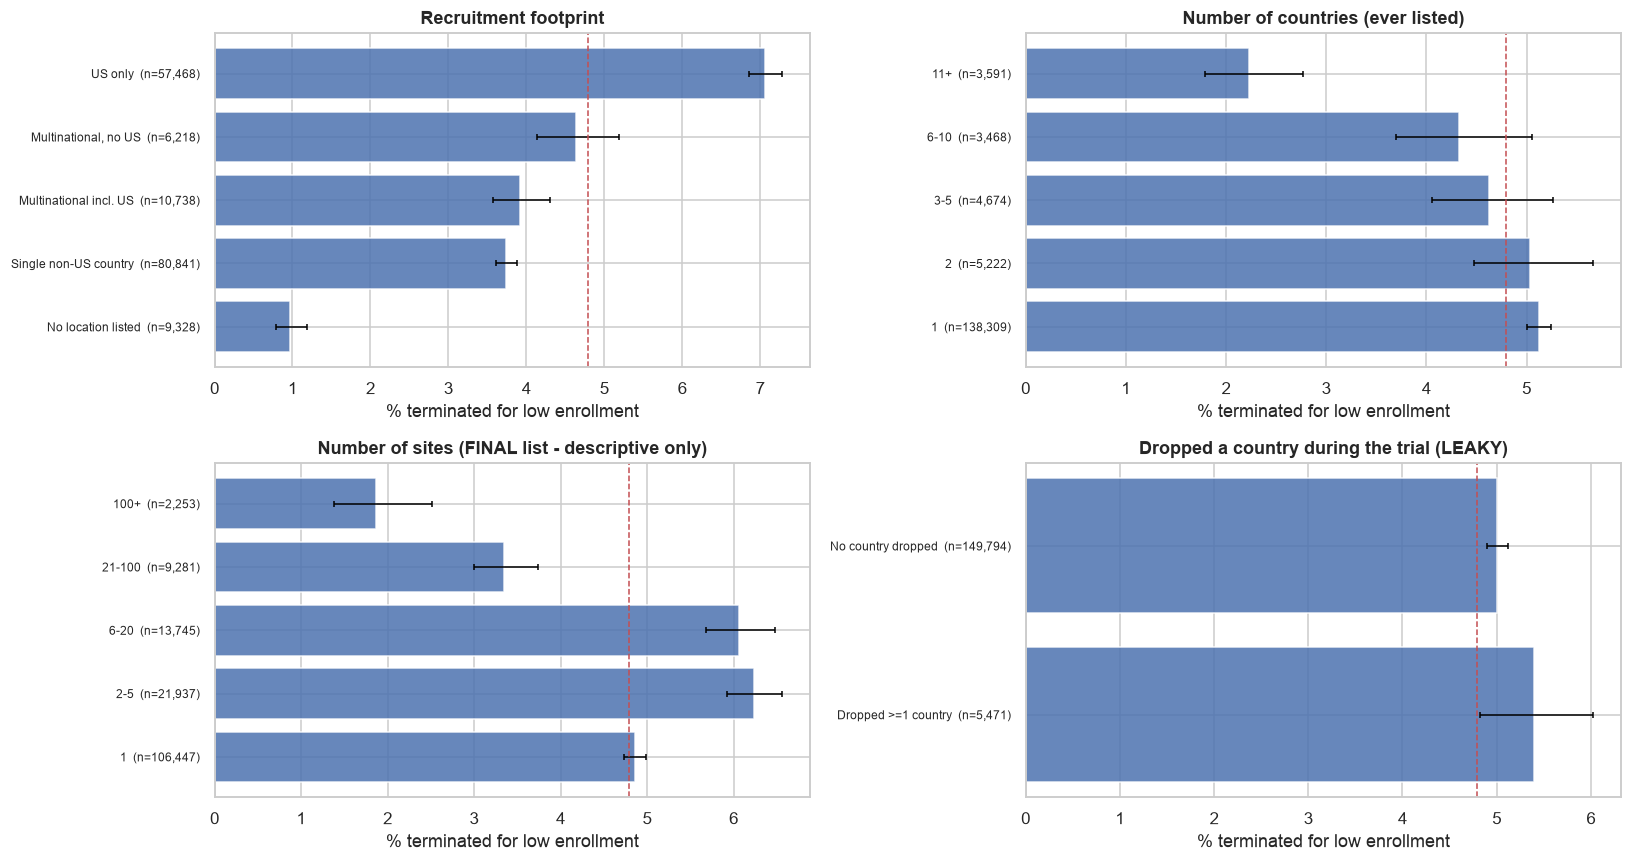

,n,k,rate,lo,hi
footprint,,,,,
No location listed,9328,90.0,0.010,0.008,0.012
Single non-US country,80841,3026.0,0.037,0.036,0.039
Multinational incl. US,10738,421.0,0.039,0.036,0.043
"Multinational, no US",6218,288.0,0.046,0.041,0.052
US only,57468,4061.0,0.071,0.069,0.073


In [3]:
def footprint(r):
    if not r.has_location: return "No location listed"
    if r.n_countries_ever == 1: return "US only" if r.has_us else "Single non-US country"
    return "Multinational incl. US" if r.has_us else "Multinational, no US"
lab["footprint"] = lab.apply(footprint, axis=1)

lab["n_countries_band"] = pd.cut(lab["n_countries_ever"], [0, 1, 2, 5, 10, 200],
                                 labels=["1", "2", "3-5", "6-10", "11+"])
fac_n = facilities.groupby("nct_id").size().rename("n_sites")
lab = lab.merge(fac_n, on="nct_id", how="left")
lab["n_sites_band"] = pd.cut(lab["n_sites"], [0, 1, 5, 20, 100, 1e6], labels=["1", "2-5", "6-20", "21-100", "100+"])
lab["dropped_country"] = np.where(lab["n_countries_removed"] > 0, "Dropped >=1 country", "No country dropped")

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
rate_bars(axes[0, 0], rates(lab, "footprint").sort_values("rate"), "Recruitment footprint")
rate_bars(axes[0, 1], rates(lab, "n_countries_band"), "Number of countries (ever listed)")
rate_bars(axes[1, 0], rates(lab, "n_sites_band"), "Number of sites (FINAL list - descriptive only)")
rate_bars(axes[1, 1], rates(lab[lab["has_location"]], "dropped_country"), "Dropped a country during the trial (LEAKY)")
plt.tight_layout(); savefig("footprint"); plt.show()
rates(lab, "footprint").sort_values("rate").round(3)

## 3. Countries

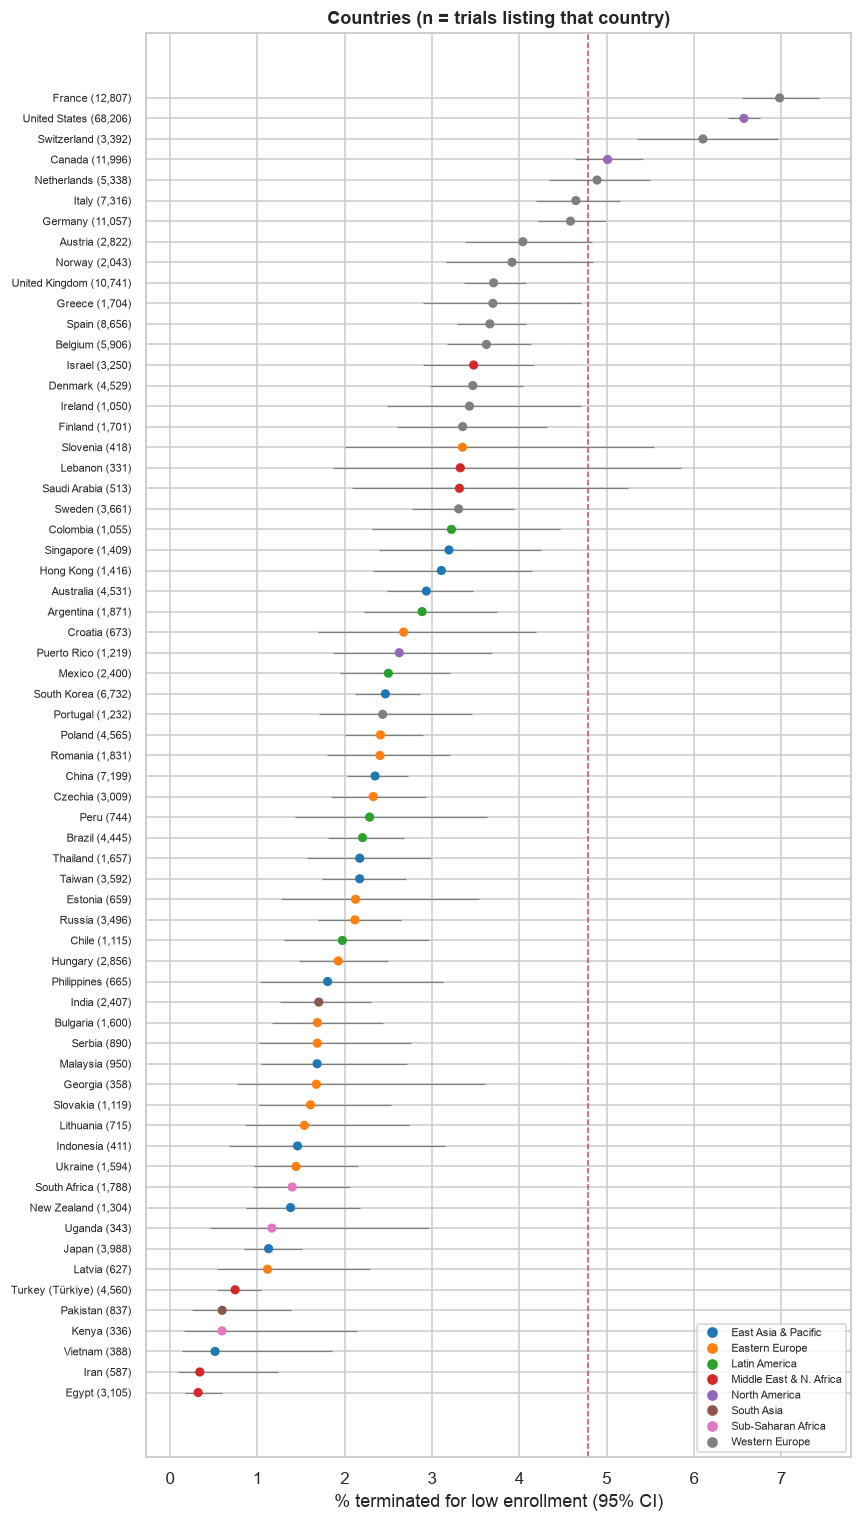

Highest:
                   n   rate
name                       
Austria         2822  0.040
Germany        11057  0.046
Italy           7316  0.046
Netherlands     5338  0.049
Canada         11996  0.050
Switzerland     3392  0.061
United States  68206  0.066
France         12807  0.070

Lowest:
                     n   rate
name                         
Egypt             3105  0.003
Iran               587  0.003
Vietnam            388  0.005
Kenya              336  0.006
Pakistan           837  0.006
Turkey (Türkiye)  4560  0.007
Latvia             627  0.011
Japan             3988  0.011


In [4]:
ctry = ever.merge(lab[["nct_id", "label"]], on="nct_id")
c = rates(ctry, "name", min_n=300)
c["iso3"] = c.index.map(lambda x: GEO[x][0])
c["region"] = c.index.map(lambda x: GEO[x][1])

fig = px.choropleth(c.reset_index(), locations="iso3", color=c["rate"].values * 100,
                    hover_name="name", hover_data={"n": True, "iso3": False},
                    color_continuous_scale="Reds", labels={"color": "% failed"},
                    title="Termination-for-enrollment rate by country (countries with >= 300 labeled trials)")
fig.update_layout(margin=dict(l=0, r=0, t=40, b=0), height=450)
fig.write_html(FIG / "geo_country_map.html", include_plotlyjs="cdn")
fig.show()

top = c.sort_values("rate")
fig, ax = plt.subplots(figsize=(8, 14))
pal = dict(zip(sorted(c["region"].unique()), sns.color_palette("tab10")))
y = np.arange(len(top))
ax.errorbar(top["rate"] * 100, y, xerr=[(top["rate"] - top["lo"]) * 100, (top["hi"] - top["rate"]) * 100],
            fmt="none", ecolor="gray", lw=0.8)
ax.scatter(top["rate"] * 100, y, c=[pal[r] for r in top["region"]], s=25, zorder=3)
ax.set_yticks(y, [f"{i} ({n:,})" for i, n in zip(top.index, top["n"])], fontsize=7)
ax.axvline(BASE * 100, ls="--", color="#C44E52", lw=1)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=v, label=k) for k, v in pal.items()], fontsize=7, loc="lower right")
ax.set_xlabel("% terminated for low enrollment (95% CI)"); ax.set_title("Countries (n = trials listing that country)")
plt.tight_layout(); savefig("countries"); plt.show()
print("Highest:"); print(top.tail(8)[["n", "rate"]].round(3).to_string())
print("\nLowest:"); print(top.head(8)[["n", "rate"]].round(3).to_string())

## 4. Regions

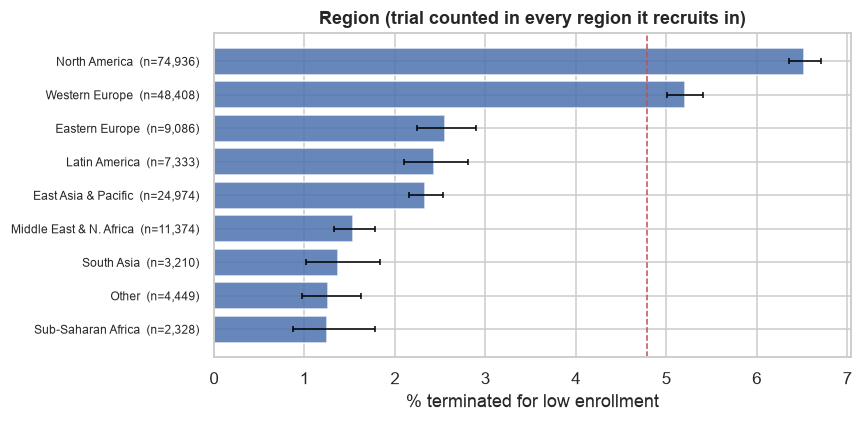

,n,k,rate,lo,hi
region,,,,,
Sub-Saharan Africa,2328,29.0,0.012,0.009,0.018
Other,4449,56.0,0.013,0.010,0.016
South Asia,3210,44.0,0.014,0.010,0.018
Middle East & N. Africa,11374,175.0,0.015,0.013,0.018
East Asia & Pacific,24974,583.0,0.023,0.022,0.025
Latin America,7333,178.0,0.024,0.021,0.028
Eastern Europe,9086,232.0,0.026,0.022,0.029
Western Europe,48408,2519.0,0.052,0.050,0.054
North America,74936,4891.0,0.065,0.064,0.067


In [5]:
reg = ever[["nct_id", "region"]].drop_duplicates().merge(lab[["nct_id", "label"]], on="nct_id")
r = rates(reg, "region").sort_values("rate")
fig, ax = plt.subplots(figsize=(8, 4))
rate_bars(ax, r, "Region (trial counted in every region it recruits in)")
plt.tight_layout(); savefig("regions"); plt.show()
r.round(3)

## 5. US states (US-only trials)

In [6]:
STATES = {"Alabama":"AL","Alaska":"AK","Arizona":"AZ","Arkansas":"AR","California":"CA","Colorado":"CO","Connecticut":"CT",
"Delaware":"DE","District of Columbia":"DC","Florida":"FL","Georgia":"GA","Hawaii":"HI","Idaho":"ID","Illinois":"IL","Indiana":"IN",
"Iowa":"IA","Kansas":"KS","Kentucky":"KY","Louisiana":"LA","Maine":"ME","Maryland":"MD","Massachusetts":"MA","Michigan":"MI",
"Minnesota":"MN","Mississippi":"MS","Missouri":"MO","Montana":"MT","Nebraska":"NE","Nevada":"NV","New Hampshire":"NH",
"New Jersey":"NJ","New Mexico":"NM","New York":"NY","North Carolina":"NC","North Dakota":"ND","Ohio":"OH","Oklahoma":"OK",
"Oregon":"OR","Pennsylvania":"PA","Rhode Island":"RI","South Carolina":"SC","South Dakota":"SD","Tennessee":"TN","Texas":"TX",
"Utah":"UT","Vermont":"VT","Virginia":"VA","Washington":"WA","West Virginia":"WV","Wisconsin":"WI","Wyoming":"WY"}
us_only = lab.loc[lab["footprint"] == "US only", ["nct_id", "label"]]
st = facilities[facilities["country"] == "United States"].assign(abbr=lambda d: d["state"].map(STATES)).dropna(subset=["abbr"])
st = st[["nct_id", "abbr"]].drop_duplicates().merge(us_only, on="nct_id")
s = rates(st, "abbr", min_n=100)

fig = px.choropleth(s.reset_index(), locations="abbr", locationmode="USA-states", scope="usa",
                    color=s["rate"].values * 100, hover_data={"n": True}, color_continuous_scale="Reds",
                    labels={"color": "% failed"}, title="US-only trials: termination-for-enrollment rate by state (n >= 100)")
fig.update_layout(margin=dict(l=0, r=0, t=40, b=0), height=420)
fig.write_html(FIG / "geo_us_states_map.html", include_plotlyjs="cdn")
fig.show()
print(f"US-only labeled trials: {len(us_only):,}, rate {us_only['label'].mean():.2%}")
print("Highest:"); print(s.sort_values("rate").tail(6)[["n", "rate"]].round(3).to_string())
print("\nLowest:"); print(s.sort_values("rate").head(6)[["n", "rate"]].round(3).to_string())

US-only labeled trials: 57,468, rate 7.07%
Highest:
         n   rate
abbr             
IL    4668  0.069
NY    8396  0.072
SD     455  0.073
NH     543  0.077
DC    1095  0.086
WY     115  0.087

Lowest:
         n   rate
abbr             
VT     375  0.029
KS    1981  0.032
ID     600  0.037
RI    1025  0.037
ME     334  0.039
NM     792  0.042


## 6. Do the patterns survive adjustment?

Footprint and region are tied to phase and sponsor (e.g. industry runs most multinational trials, and industry
trials fail less). Logistic regression with phase, lead sponsor class and start year as controls shows whether the
geographic differences are real or just reflect *who* runs trials *where*.

In [7]:
m = lab[lab["has_location"]].copy()
m["phase"] = m["phase"].fillna("NA")
m = m[m["lead_sponsor_class"].isin(["INDUSTRY", "OTHER", "NIH", "OTHER_GOV", "NETWORK", "FED"])]
m = m.astype({"phase": object, "lead_sponsor_class": object, "footprint": object})
m["year_c"] = m["start_year"] - 2014  # centred for numerical stability

def odds_ratios(formula, data, keep):
    fit = smf.logit(formula, data=data).fit(disp=0)
    ci = np.exp(fit.conf_int()); ci.columns = ["lo", "hi"]
    out = pd.DataFrame({"OR": np.exp(fit.params)}).join(ci)
    return out[out.index.str.contains(keep)].round(2)

ref = "C(footprint, Treatment('US only'))"
crude = odds_ratios(f"label ~ {ref}", m, "footprint")
adj = odds_ratios(f"label ~ {ref} + C(phase) + C(lead_sponsor_class) + year_c", m, "footprint")
tbl = crude.add_prefix("crude_").join(adj.add_prefix("adj_"))
tbl.index = tbl.index.str.extract(r"\[T\.(.*)\]")[0]
print("Odds ratio vs US-only trials (OR < 1 = lower failure odds)")
tbl

Odds ratio vs US-only trials (OR < 1 = lower failure odds)


,crude_OR,crude_lo,crude_hi,adj_OR,adj_lo,adj_hi
0,,,,,,
Multinational incl. US,0.54,0.48,0.59,0.66,0.59,0.74
"Multinational, no US",0.64,0.57,0.72,0.72,0.64,0.82
Single non-US country,0.51,0.49,0.54,0.51,0.48,0.53


In [8]:
# Same check for number of countries (log scale), the single most-cited 'geographic' feature
m = m[m["n_countries_ever"] > 0]  # one trial lists a country with a blank name
m["log_n_countries"] = np.log2(m["n_countries_ever"].astype(float))
print("non-finite values:", (~np.isfinite(m["log_n_countries"])).sum())
for f in ["label ~ log_n_countries",
          "label ~ log_n_countries + C(phase) + C(lead_sponsor_class) + year_c"]:
    print(f, "\n", odds_ratios(f, m, "log_n_countries").to_string(), "\n")

non-finite values: 0
label ~ log_n_countries 
                    OR    lo    hi
log_n_countries  0.88  0.85  0.91 



label ~ log_n_countries + C(phase) + C(lead_sponsor_class) + year_c 
                    OR   lo    hi
log_n_countries  0.93  0.9  0.97 



## 7. Reporting bias check

A country can look "safe" simply because its trials rarely update their status to TERMINATED, ending as
UNKNOWN (and so dropping out of the label) instead. Compare each country's UNKNOWN share with its failure rate.

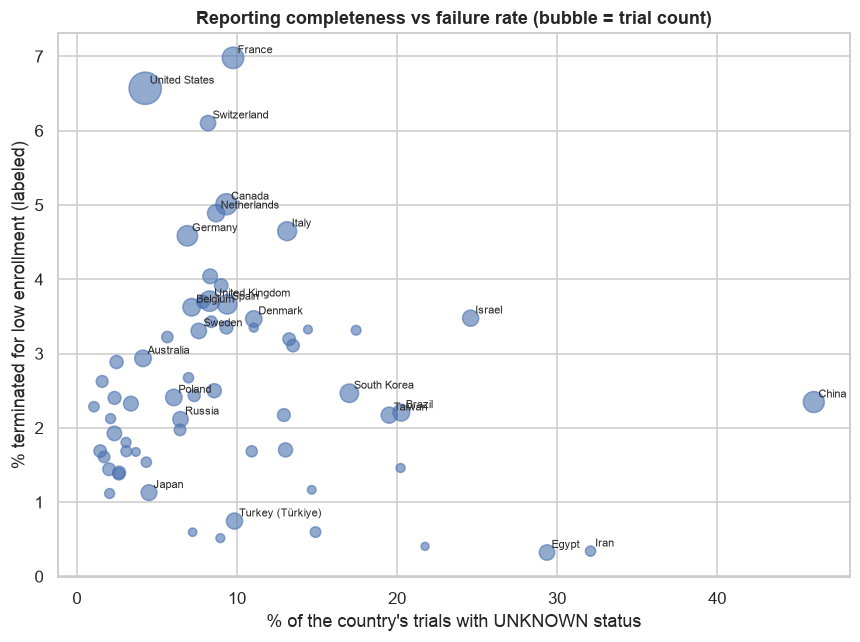

,n,pct_unknown,pct_terminated_any,pct_failed
name,,,,
United States,89142,4.3,13.7,6.6
France,17488,9.8,14.5,7.0
United Kingdom,14156,8.3,12.0,3.7
Japan,5017,4.5,9.6,1.1
China,15854,46.0,3.6,2.3
Brazil,6557,20.3,7.3,2.2
Egypt,4600,29.4,1.2,0.3
Turkey (Türkiye),5575,9.8,4.5,0.7


In [9]:
allst = pd.read_parquet(ROOT / "data/processed/trials.parquet", columns=["nct_id", "overall_status", "label"])
cm = ever[["nct_id", "name"]].merge(allst, on="nct_id")
rep = cm.groupby("name").agg(n=("nct_id", "size"),
                             pct_unknown=("overall_status", lambda s: (s == "UNKNOWN").mean() * 100),
                             pct_terminated_any=("overall_status", lambda s: (s == "TERMINATED").mean() * 100),
                             pct_failed=("label", lambda s: s.mean() * 100))
rep = rep[rep["n"] >= 300].sort_values("pct_failed")
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(rep["pct_unknown"], rep["pct_failed"], s=np.sqrt(rep["n"]) * 1.5, alpha=0.6)
for name, r in rep.iterrows():
    if r["n"] > 4000 or r["pct_unknown"] > 25:
        ax.annotate(name, (r["pct_unknown"], r["pct_failed"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("% of the country's trials with UNKNOWN status"); ax.set_ylabel("% terminated for low enrollment (labeled)")
ax.set_title("Reporting completeness vs failure rate (bubble = trial count)")
plt.tight_layout(); savefig("reporting_bias"); plt.show()
rep.loc[["United States", "France", "United Kingdom", "Japan", "China", "Brazil", "Egypt", "Turkey (Türkiye)"]].round(1)

## 8. Summary of findings

**Footprint**
- **US-only trials fail most often: 7.1%**, versus 3.7% for single-country non-US trials and 3.9–4.6% for multinational trials.
  After adjusting for phase, sponsor type and start year, non-US and multinational trials still have roughly
  **0.5–0.7× the odds** of failing compared with US-only trials, so this is not just "industry runs the big trials".
- **More countries → lower failure.** Each doubling of the number of countries lowers the odds by ~12% crude, ~7% adjusted
  (OR 0.93, 95% CI 0.90–0.97). Trials in 11+ countries fail 2.2% of the time vs 5.1% for single-country trials.
- **Sites (final list) show an inverted U:** 2–20 sites fail most (~6%), 100+ sites fail least (1.9%). The final site
  list is leaky (failing trials stop opening sites), so this is descriptive only.
- Trials that **dropped a country** fail slightly more (5.4% vs 5.0%), but this is itself a post-start event — exclude from modeling.
- **9,328 trials (5.7%) list no location at all, and only 1.0% of them fail.** Missing location is a marker of
  registration style, not geography; it should be a separate category or a data-quality flag, never imputed.

**Countries and regions**
- North America (6.5%) and Western Europe (5.2%) are far above every other region (1.2–2.6%).
- Highest countries: France (7.0%), United States (6.6%), Switzerland (6.1%). Lowest: Egypt, Iran (0.3%), Turkey (0.7%), Japan (1.1%).
- Within the US (US-only trials), states range from ~3% (VT, KS) to ~9% (DC, WY); most large states sit near 7%.

**Caution — reporting bias**
- Low-failure countries are often low-*reporting* countries: **46% of trials involving China and 29% in Egypt have UNKNOWN status**
  (vs 4% in the US). Those trials drop out of the label, so their true failure rate is unknown. Japan is the
  exception (low UNKNOWN share *and* low failure), which may be a real effect.
- So "US trials fail more" partly means "US trials report failure more completely" (FDAAA reporting rules).
  The competing-risks / survival analysis should treat UNKNOWN as censored rather than dropping it.

**Implications for the model**
- Usable geographic features (once rebuilt from registration-time records): US-only flag, number of countries planned,
  region set, and a missing-location flag.
- Do not use: final site counts, dropped-country flags.
- Report geographic results with the reporting-bias caveat, and run a sensitivity analysis restricted to countries with < 10% UNKNOWN.